In [1]:
# =========================
# Standard libraries
# =========================
import os
import json
import random
import pickle
import warnings
import math
import re

from datetime import datetime

warnings.filterwarnings("ignore")


# =========================
# Data processing
# =========================
import numpy as np
import pandas as pd
import geopandas as geopd


# =========================
# Geometry / GIS
# =========================
import shapely.wkt as wkt

from shapely.geometry import LineString, Polygon, Point

import mapclassify


# =========================
# Visualization
# =========================
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.colors as mcolors

from matplotlib import cm
from matplotlib.colors import (
    LinearSegmentedColormap,
    BoundaryNorm,
    Normalize,
)
from matplotlib.colorbar import ColorbarBase
from mpl_toolkits.axes_grid1 import make_axes_locatable



# =========================
# Display settings
# =========================
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": [
        "Times New Roman",   # Prefer if installed
        "Liberation Serif",  # Common on Ubuntu / Debian
        "Nimbus Roman",      # Common with TeX / Ghostscript
        "DejaVu Serif"       # Matplotlib fallback
    ],
    "mathtext.fontset": "stix",       # Math symbols closer to Times
    "axes.unicode_minus": False,
})

pd.set_option("display.max_columns", None)

In [6]:
df = pd.read_pickle('../../../../Data/e2018.pkl')
df.rename(columns={'BADGE':'badge'},inplace=True)
df.rename(columns={'DATE_RD':'date'},inplace=True)
df1 = pd.read_csv("../../../../Data/household_data/badge_location.csv")
df = pd.merge(df,df1[['badge','tractID','blockID']],on='badge',how='left')
df["date"] = pd.to_datetime(df["date"], errors="coerce")
df = df[df["date"].dt.month == 4]
df = df.dropna(subset=["blockID", "tractID"]).reset_index(drop=True)
df["blockID"] = df["blockID"].astype(int)
df["tractID"] = df["tractID"].astype(int)
df["blockID"] = df["blockID"].astype(str)
df['blockgroupID'] = df['blockID'].str[:5]
df["tractID"] = df["tractID"].astype(str)
df.index = range(df.shape[0])
df.head(2)

,badge,date,INT_VALUE_0000,INT_VALUE_0030,INT_VALUE_0100,INT_VALUE_0130,INT_VALUE_0200,INT_VALUE_0230,INT_VALUE_0300,INT_VALUE_0330,INT_VALUE_0400,INT_VALUE_0430,INT_VALUE_0500,INT_VALUE_0530,INT_VALUE_0600,INT_VALUE_0630,INT_VALUE_0700,INT_VALUE_0730,INT_VALUE_0800,INT_VALUE_0830,INT_VALUE_0900,INT_VALUE_0930,INT_VALUE_1000,INT_VALUE_1030,INT_VALUE_1100,INT_VALUE_1130,INT_VALUE_1200,INT_VALUE_1230,INT_VALUE_1300,INT_VALUE_1330,INT_VALUE_1400,INT_VALUE_1430,INT_VALUE_1500,INT_VALUE_1530,INT_VALUE_1600,INT_VALUE_1630,INT_VALUE_1700,INT_VALUE_1730,INT_VALUE_1800,INT_VALUE_1830,INT_VALUE_1900,INT_VALUE_1930,INT_VALUE_2000,INT_VALUE_2030,INT_VALUE_2100,INT_VALUE_2130,INT_VALUE_2200,INT_VALUE_2230,INT_VALUE_2300,INT_VALUE_2330,address,district,tractID,blockID,blockgroupID
0,E162956,2018-04-01,1.62,1.45,1.44,1.59,1.18,0.75,0.95,0.80,0.79,0.75,0.76,0.77,0.89,0.78,1.16,2.04,3.90,2.18,0.80,0.34,0.31,0.13,0.14,0.26,0.22,0.38,0.14,0.29,0.11,0.14,0.16,0.15,0.26,0.14,0.17,0.17,0.19,0.28,0.24,0.17,0.17,0.14,0.22,0.30,0.14,0.13,0.15,0.31,46.0,POINT (-84.30334 30.388433),1801,18011011,18011
1,E162956,2018-04-02,0.17,0.15,0.16,0.27,0.13,0.16,0.11,0.13,0.29,0.12,0.14,0.10,0.31,0.09,0.18,0.55,0.88,0.60,0.54,0.52,0.88,0.21,0.61,1.87,2.68,2.51,2.52,2.25,0.17,0.42,0.18,0.18,0.31,0.22,0.33,0.27,0.66,0.11,0.42,0.49,1.00,0.92,0.26,0.34,0.64,0.21,0.38,0.16,46.0,POINT (-84.30334 30.388433),1801,18011011,18011


In [8]:
df.shape

(1654367, 55)

In [2]:
boundary_block = pd.read_csv('../../../../Data/boundary_data/tal_block_boundary.csv')
boundary_block["geometry"] = geopd.GeoSeries.from_wkt(boundary_block["geometry"])
boundary_block = geopd.GeoDataFrame(boundary_block, crs="EPSG:4326")
boundary_block["centroid"] = geopd.GeoSeries.from_wkt(boundary_block["centroid"])
boundary_block.head(2)

,tractID,blockID,geoID,geometry,centroid
0,2505,25054048,120730025054048,"POLYGON ((-84.21645 30.45289, -84.21638 30.452...",POINT (-84.21505 30.45322)
1,1801,18012017,120730018012017,"POLYGON ((-84.29834 30.39439, -84.29822 30.394...",POINT (-84.28963 30.39094)


In [3]:
boundary_block_group = boundary_block.copy()
boundary_block_group["blockgroupID"] = boundary_block_group["blockID"].astype(str).str[:5]
boundary_block_group = boundary_block_group[['tractID','blockID','blockgroupID','geoID','geometry','centroid']]

In [5]:
print(boundary_block_group['tractID'].nunique())
print(boundary_block_group['blockgroupID'].nunique())
print(boundary_block_group['blockID'].nunique())


56
147
3941


In [6]:
id_cols = ["badge", "date", "address", "district", "tractID", "blockID",'blockgroupID']

value_cols = [c for c in df.columns if c.startswith("INT_VALUE_")]
# 若 df 构造时保证列顺序就是 0000→2330，可不用再 sort；否则会乱序时按时间后缀排序更安全：
value_cols = sorted(value_cols)

assert len(value_cols) == 48, len(value_cols)

# 形状 (行数, 6 个四小时段, 每段 8 个半小时点) → 在最后一维求和 → (行数, 6)
arr_4h = df[value_cols].to_numpy(dtype="float64").reshape(len(df), 6, 8).sum(axis=2)

new_cols = [
    "INT_4h_1",  # 00:00–03:30
    "INT_4h_2",
    "INT_4h_3",
    "INT_4h_4",
    "INT_4h_5",
    "INT_4h_6",
]

df1 = pd.concat([df[id_cols].reset_index(drop=True), pd.DataFrame(arr_4h, columns=new_cols)], axis=1)

In [7]:
import pandas as pd
import numpy as np

value_cols = [f"INT_4h_{i}" for i in range(1, 7)]
meta_cols = ["address", "district", "tractID", "blockID",'blockgroupID']

base = df1.copy()
base["day"] = pd.to_datetime(base["date"], errors="coerce").dt.normalize()

# （可选）同一天同一 badge 若有多条，先按业务规则聚合：这里用最常见的“求和”，你可改成 mean/first 等。
base = (
    base.groupby(["badge", "day"], as_index=False)[value_cols + meta_cols]
    .agg({**{c: "sum" for c in value_cols}, **{c: "first" for c in meta_cols}})
)

badges = np.sort(base["badge"].unique())

# TODO: 用你的 30 天替换这里（要包含你希望对齐的那 30 个 calendar day）
day_range = pd.date_range("2018-04-01", periods=30, freq="D").normalize()

idx = pd.MultiIndex.from_product([badges, day_range], names=["badge", "day"])

wide06 = (
    base.set_index(["badge", "day"])[value_cols]
    .reindex(idx)
    .fillna(0)
)

# （可选自检）理论上每个 badge 正好 30 行 × 6 列 → 180
assert wide06.groupby(level=0).size().eq(30).all(), "badge-day 不完整，请检查 day_range"

# （badge，day）已按字典序：先 badge，再日期；对每个 badge，30 天的 6 列按行展开成 180
n_badge = badges.size
n_day = day_range.size
arr180 = wide06.to_numpy(dtype=float).reshape(n_badge, n_day * 6)

# 列名也可用 f"{day}_{k}"；这里给一个简单的 t000 ~ t179
col180 = [f"t{i:03d}" for i in range(180)]

meta = (
    base.sort_values(["badge", "day"])
        .drop_duplicates("badge")
        .set_index("badge")[meta_cols]
    .reindex(badges)  # 与 badges 对齐
)

df2 = pd.concat(
    [
        meta,
        pd.DataFrame(arr180, index=badges, columns=col180),
    ],
    axis=1,
).reset_index(names="badge")   # pandas>=2；若报错可改成 reset_index().rename(...)

In [8]:
import re
feat_cols = [c for c in df2.columns if re.fullmatch(r"t\d+", str(c))]
feat_cols = sorted(feat_cols)  # t000,t001,...,t179
X = df2[feat_cols].to_numpy(dtype=np.float64)  # 形状 (N, 180)
assert X.shape[1] == 180
assert X.shape[0] == len(df2)

z = np.asarray(X, dtype=float).ravel()
z = z[np.isfinite(z)]
thresh_high = np.quantile(z, 0.90)    
print(f"90% 阈值: {thresh_high:.2f}")

thresh_low = np.quantile(z, 0.05)    
print(f"5% 阈值: {thresh_low:.2f}")    

90% 阈值: 9.98
5% 阈值: 0.12


In [9]:
import re
import numpy as np
# 选出 180 个特征列（按你实际的列命名改这里的规则）
feat_cols = [c for c in df2.columns if re.fullmatch(r"t\d+", str(c))]
feat_cols = sorted(feat_cols, key=lambda x: int(str(x)[1:]))
assert len(feat_cols) == 180, len(feat_cols)
X = df2[feat_cols].to_numpy(dtype=float)
# 每个 badge（每一行）：180 个数里有多少 > thresh
prop = np.mean(X > thresh_high, axis=1)
df2["prop_high"] = prop

In [10]:
import re
import numpy as np
# 选出 180 个特征列（按你实际的列命名改这里的规则）
feat_cols = [c for c in df2.columns if re.fullmatch(r"t\d+", str(c))]
feat_cols = sorted(feat_cols, key=lambda x: int(str(x)[1:]))
assert len(feat_cols) == 180, len(feat_cols)
X = df2[feat_cols].to_numpy(dtype=float)
# 每个 badge（每一行）：180 个数里有多少 > thresh
prop = np.mean(X <= thresh_low, axis=1)
df2["prop_low"] = prop

In [11]:
import re
import numpy as np
# 选出 180 个特征列（按你实际的列命名改这里的规则）
feat_cols = [c for c in df2.columns if re.fullmatch(r"t\d+", str(c))]
feat_cols = sorted(feat_cols, key=lambda x: int(str(x)[1:]))
assert len(feat_cols) == 180, len(feat_cols)
X = df2[feat_cols].to_numpy(dtype=float)
# 每个 badge（每一行）：180 个数里有多少 > thresh
prop = np.mean(X > thresh_high, axis=1)
df2["prop_high"] = prop

In [12]:
df4 = df2[['badge','blockgroupID','prop_high','prop_low']]
df4 = (
    df4.groupby("blockgroupID", as_index=False)[["prop_high", "prop_low"]]
    .mean(numeric_only=True)
)

In [13]:
geo = geopd.GeoDataFrame(boundary_block_group).copy()
df4['blockgroupID'] = df4['blockgroupID'].astype(int)
df4['blockgroupID'] = df4['blockgroupID'].astype(str)
geo['blockgroupID'] = geo['blockgroupID'].astype(str)
geo_data = geo.merge(
    df4[["blockgroupID","prop_high","prop_low"]],
    left_on="blockgroupID",
    right_on="blockgroupID",
    how="left",
)
geo_data = geo_data.dropna(subset=["prop_high","prop_low"])
geo_data = geo_data.drop_duplicates(subset=["blockgroupID"])
geo_data.index = range(geo_data.shape[0])
print(geo_data.shape)
geo_data.head(2)

(145, 8)


,tractID,blockID,blockgroupID,geoID,geometry,centroid,prop_high,prop_low
0,2505,25054048,25054,120730025054048,"POLYGON ((-84.21645 30.45289, -84.21638 30.452...",POINT (-84.21505 30.45322),0.086293,0.047528
1,1801,18012017,18012,120730018012017,"POLYGON ((-84.29834 30.39439, -84.29822 30.394...",POINT (-84.28963 30.39094),0.083186,0.093043


In [15]:
census_df = pd.read_csv('../../../../Data/census_data/tal_census.csv')
census_df.head(2)


,pop_total,households,age_median,male_ratio,white_ratio,inc_median_ind,inc_median_household,inc_per_capita,low_income_ratio,work_from_home_ratio,bachelor_or_above_ratio,rent_median,property_value_median,tract_fips,full_ct_fips
0,2301,1248,29.7,0.456758,0.630595,28998,40273,26214,0.175899,0.035320,0.278575,1027,145200,903,12073000903
1,3549,1883,32.9,0.454494,0.654269,34409,46715,32549,0.115210,0.029974,0.335024,1000,144000,904,12073000904


In [17]:
df5 = geo_data[['tractID','blockgroupID','prop_high','prop_low']]
df5['ano_prop'] = df5['prop_high'] + df5['prop_low']
df5['tractID'] = df5['tractID'].astype(str)
census_df['tract_fips'] = census_df['tract_fips'].astype(str)
df5 = df5.merge(
    census_df[['tract_fips', 'inc_median_household', "property_value_median","bachelor_or_above_ratio","work_from_home_ratio"]],
    left_on='tractID',
    right_on='tract_fips',
    how='left'
)
df5 = df5.drop(columns='tract_fips')
df5['prop_low'] = df5['prop_low'] * 100
df5 = df5[df5['inc_median_household'] > 0]
df5 = df5[df5['property_value_median'] > 0]
df5 = df5[df5['bachelor_or_above_ratio'] > 0]
df5 = df5[df5['work_from_home_ratio'] > 0]
df5 = df5[df5['prop_low'] < 30]

df5.head(10)

,tractID,blockgroupID,prop_high,prop_low,ano_prop,inc_median_household,property_value_median,bachelor_or_above_ratio,work_from_home_ratio
0,2505,25054,0.086293,4.752811,0.133821,60758,193300,0.360360,0.013720
2,1901,19011,0.076164,8.989518,0.166059,23274,118800,0.131363,0.026125
3,1001,10011,0.100057,15.428005,0.254337,27118,110800,0.105087,0.009464
4,302,30210,0.043588,4.928315,0.092871,56076,154900,0.402217,0.090285
5,2513,25131,0.091421,2.148413,0.112905,105786,247400,0.391069,0.056138
6,2201,22012,0.389846,5.098765,0.440833,41771,110200,0.178646,0.028422
7,2104,21041,0.064325,7.124656,0.135572,24844,136000,0.085323,0.038148
8,2003,20031,0.340402,12.691310,0.467315,30474,116900,0.046068,0.016336
9,2512,25122,0.131925,2.512686,0.157052,92043,277600,0.309312,0.031794
10,2207,22071,0.097069,6.861572,0.165684,42080,132600,0.123697,0.009236


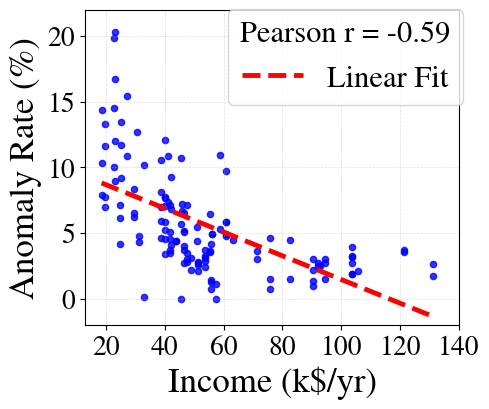

In [26]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import pearsonr

# 每个 blockgroupID 保留一个点
plot_df = (
    df5.groupby("blockgroupID", as_index=False)
       .agg({
           "inc_median_household": "first",
           "prop_low": "mean"
       })
       .dropna(subset=["inc_median_household", "prop_low"])
)

x = plot_df["inc_median_household"] / 1000  # 美元转换为千美元
y = plot_df["prop_low"]

# Pearson correlation
r, p = pearsonr(x, y)

# Linear fit
slope, intercept = np.polyfit(x, y, 1)
x_fit = np.linspace(x.min(), x.max(), 200)
y_fit = slope * x_fit + intercept

# Plot
# Plot
fig, ax = plt.subplots(figsize=(5, 4.2))

ax.scatter(
    x, y,
    s=20,
    color="blue",
    alpha=0.8
)

ax.plot(
    x_fit, y_fit,
    color="red",
    linestyle="--",
    linewidth=3.5,
    label="Linear Fit"
)

ax.set_xlabel("Income (k$/yr)", fontsize=25)
ax.set_ylabel("Anomaly Rate (%)", fontsize=25)
ax.set_ylim(-2, 22)
ax.set_xticks([20, 40, 60, 80, 100, 120, 140])
ax.tick_params(axis="x", labelsize=20)
ax.tick_params(axis="y", labelsize=20)

ax.legend(
    title=f"Pearson r = {r:.2f}",
    loc='upper right',
    bbox_to_anchor=(1.05, 1.05), 
    frameon=True,
    fontsize=22,          # legend 文字
    title_fontsize=22     # legend 标题（Pearson r = ...）
)

ax.grid(True, linestyle="--", linewidth=0.5, alpha=0.4)

plt.tight_layout()
plt.savefig(f"../../../Analysis/Plot/Motivation/socialeconomy/income_rate.png", dpi=300)
plt.show()

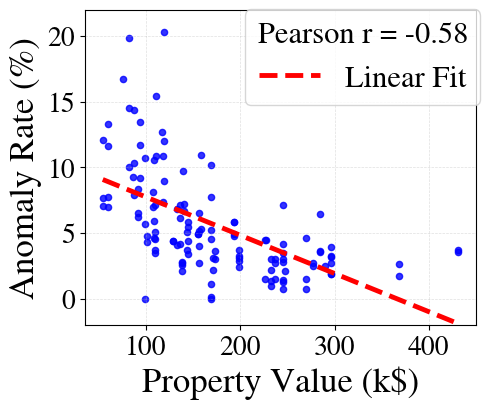

In [27]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import pearsonr
plot_df = (
    df5.groupby("blockgroupID", as_index=False)
       .agg({
           "property_value_median": "first",
           "prop_low": "mean"
       })
       .dropna(subset=["property_value_median", "prop_low"])
)
x = plot_df["property_value_median"] / 1000   # 千美元
y = plot_df["prop_low"]
r, p = pearsonr(x, y)
slope, intercept = np.polyfit(x, y, 1)
x_fit = np.linspace(x.min(), x.max(), 200)
y_fit = slope * x_fit + intercept
fig, ax = plt.subplots(figsize=(5, 4.2))
ax.scatter(x, y, s=20, color="blue", alpha=0.8)
ax.plot(x_fit, y_fit, color="red", linestyle="--", linewidth=3.5, label="Linear Fit")
ax.set_xlabel("Property Value (k$)", fontsize=25)
ax.set_ylabel("Anomaly Rate (%)", fontsize=25)
ax.set_ylim(-2, 22)
ax.set_xticks([100,  200,  300,400])
ax.tick_params(axis="x", labelsize=20)
ax.tick_params(axis="y", labelsize=20)
ax.legend(
    title=f"Pearson r = {r:.2f}",
    loc="upper right",
    bbox_to_anchor=(1.05, 1.05),
    frameon=True,
    fontsize=22,
    title_fontsize=22
)
ax.grid(True, linestyle="--", linewidth=0.5, alpha=0.4)
plt.tight_layout()
plt.savefig(f"../../../Analysis/Plot/Motivation/socialeconomy/property_value_rate.png", dpi=300)
plt.show()

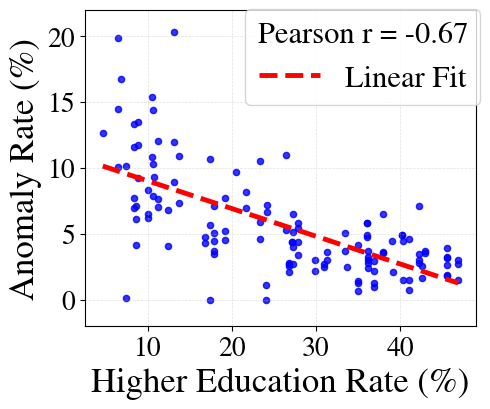

In [30]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import pearsonr
plot_df = (
    df5.groupby("blockgroupID", as_index=False)
       .agg({
           "bachelor_or_above_ratio": "first",
           "prop_low": "mean"
       })
       .dropna(subset=["bachelor_or_above_ratio", "prop_low"])
)
x = plot_df["bachelor_or_above_ratio"] * 100
y = plot_df["prop_low"]
r, p = pearsonr(x, y)
slope, intercept = np.polyfit(x, y, 1)
x_fit = np.linspace(x.min(), x.max(), 200)
y_fit = slope * x_fit + intercept
fig, ax = plt.subplots(figsize=(5, 4.2))
ax.scatter(x, y, s=20, color="blue", alpha=0.8)
ax.plot(x_fit, y_fit, color="red", linestyle="--", linewidth=3.5, label="Linear Fit")
ax.set_xlabel("Higher Education Rate (%)", fontsize=25)
ax.set_ylabel("Anomaly Rate (%)", fontsize=25)
ax.set_ylim(-2, 22)
ax.set_xticks([10, 20, 30, 40])
ax.tick_params(axis="x", labelsize=20)
ax.tick_params(axis="y", labelsize=20)
ax.legend(
    title=f"Pearson r = {r:.2f}",
    loc="upper right",
    bbox_to_anchor=(1.05, 1.05),
    frameon=True,
    fontsize=22,
    title_fontsize=22
)
ax.grid(True, linestyle="--", linewidth=0.5, alpha=0.4)
plt.tight_layout()
plt.savefig(f"../../../Analysis/Plot/Motivation/socialeconomy/education_rate.png", dpi=300)
plt.show()

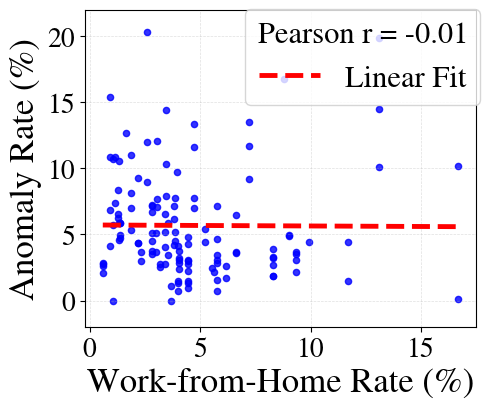

In [31]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import pearsonr

plot_df = (
    df5.groupby("blockgroupID", as_index=False)
       .agg({
           "work_from_home_ratio": "first",
           "prop_low": "mean"
       })
       .dropna(subset=["work_from_home_ratio", "prop_low"])
)

x = plot_df["work_from_home_ratio"] * 100
y = plot_df["prop_low"]

r, p = pearsonr(x, y)

slope, intercept = np.polyfit(x, y, 1)
x_fit = np.linspace(x.min(), x.max(), 200)
y_fit = slope * x_fit + intercept

fig, ax = plt.subplots(figsize=(5, 4.2))

ax.scatter(x, y, s=20, color="blue", alpha=0.8)
ax.plot(x_fit, y_fit, color="red", linestyle="--", linewidth=3.5, label="Linear Fit")

ax.set_xlabel("Work-from-Home Rate (%)", fontsize=25)
ax.set_ylabel("Anomaly Rate (%)", fontsize=25)
ax.set_ylim(-2, 22)
ax.set_xticks([0, 5, 10, 15])
ax.tick_params(axis="x", labelsize=20)
ax.tick_params(axis="y", labelsize=20)

ax.legend(
    title=f"Pearson r = {r:.2f}",
    loc="upper right",
    bbox_to_anchor=(1.05, 1.05),
    frameon=True,
    fontsize=22,
    title_fontsize=22
)

ax.grid(True, linestyle="--", linewidth=0.5, alpha=0.4)
plt.tight_layout()
plt.savefig(f"../../../Analysis/Plot/Motivation/socialeconomy/work_from_home_rate.png", dpi=300)
plt.show()